# Ocular dominance and pRF figures

- Figure 1: proportion of vertices preferring each eye
- Figure 2: strength of the ocular dominance (OD index)
- Figure 3: ocular dominance vs interocular acuity difference (ΔlogMAR)
- Figure 4: pRF size and pCM as a function of eccentricity, for each eye

Data: new pRF fits (`prfmodel`), BarsBarsRingsWedges, fsnative. Vertex selection, weights and statistics as in `od_group_figure_v12.ipynb`. Choose the version of sub-05 in the settings cell (`sub05_version`). Figures saved in `Desktop/fig_od`.

In [1]:
# Stop warnings
import warnings
warnings.filterwarnings("ignore")

# General imports
import os
import sys
import numpy as np
import pandas as pd
from scipy import stats, integrate
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Personal imports
sys.path.append("{}/../../analysis_code/utils".format(os.getcwd()))
from settings_utils import load_settings
from pycortex_utils import set_pycortex_config_file, get_rois, load_surface_pycortex
from plot_utils import plotly_template

# Project plotting functions (amblyo7T_prf/utils/plot_utils.py, same module name as analysis_code/utils/plot_utils.py)
import importlib.util
spec = importlib.util.spec_from_file_location('project_plot_utils', '{}/../utils/plot_utils.py'.format(os.getcwd()))
project_plot_utils = importlib.util.module_from_spec(spec)
spec.loader.exec_module(project_plot_utils)

In [2]:
# Directories
main_dir = '/Users/uriel/disks/meso_shared'
project_dir = 'amblyo7T_prf'
pp_dir = '{}/{}/derivatives/pp_data'.format(main_dir, project_dir)
fig_dir = '/Users/uriel/Desktop/fig_od'
cache_dir = '/Users/uriel/Desktop/fig_od/od_glm_common_cache'       # per-run GLM sums (od_glm_common_analysis.ipynb)
os.makedirs(fig_dir, exist_ok=True)

# Settings
base_dir = os.path.abspath(os.path.join(os.getcwd(), "../../"))
settings = load_settings([os.path.join(base_dir, project_dir, f) for f in
                          ["settings.yml", "prf-analysis.yml", "figure-settings.yml"]])
analysis_info = settings[0]
# sub-05: eye labels uncertain (see od_prf_sub05_versions.ipynb)
# 'as labelled' = current BIDS labels, 'swapped' = left and right exchanged, 'excluded' = not analysed
sub05_version = 'as labelled'
patients = [s for s in analysis_info['group-patient'] if not (s == 'sub-05' and sub05_version == 'excluded')]
controls = analysis_info['group-control']
subjects = patients + controls                 # analysed subjects = the two groups (not analysis_info['subjects'])
maps_names_css = analysis_info['maps_names_css']
maps_names_css_stats = analysis_info['maps_names_css_stats']
maps_names_css_od = analysis_info['maps_names_css_od']

# Analysis
task = 'BarsBarsRingsWedges'
file_spec = '{}/{}/fsnative/prfmodel/prf_derivatives/{}_task-{}{}_hemi-{}_fmriprep_dct_psc_concat_prf-css_{}.func.gii'
rois_to_keep = ['V1', 'V2', 'V3', 'V4', 'V3A', 'V3B', 'LO1', 'LO2']
eyes = {'L': 'LeftEye', 'R': 'RightEye'}

# prf_analysis filters (applied to both eyes)
ecc_th = analysis_info['ecc_th']
size_th = analysis_info['size_th']
n_th = analysis_info['n_th']
rsqr_th = analysis_info['rsqr_th']
amp_th = analysis_info['prf_amp_th']
amp_th = amp_th['psc'] if isinstance(amp_th, dict) else amp_th
stats_th = analysis_info['stats_th']
p_name = 'corr_pvalue_5pt' if stats_th == 0.05 else 'corr_pvalue_1pt'

# Amblyopic eye of each patient
participants = pd.read_csv('{}/{}/participants.tsv'.format(main_dir, project_dir), sep='\t')
ambly_eye = {s: str(e).split(' ')[0] for s, e in zip(participants.participant_id, participants.amblyopic_eye)
             if str(e).split(' ')[0] in ('L', 'R')}

# Eye scanned first (read only: sourcedata/participant-mapping.md + participant_mapping.tsv)
src_dir = '{}/{}/sourcedata'.format(main_dir, project_dir)
mapping = pd.read_csv('{}/participant_mapping.tsv'.format(src_dir), sep='\t', dtype=str).dropna(subset=['initials'])
initials_to_sub = {i.strip(): b.strip() for i, b in zip(mapping.initials, mapping.bids_name)}
first_eye = {}
with open('{}/participant-mapping.md'.format(src_dir)) as f:
    for line in f:
        if 'eye first' in line:
            initials, txt = line.split(',', 1)
            first_eye[initials_to_sub[initials.strip()]] = 'L' if 'LEFT' in txt.upper() else 'R'

# Pycortex database (ROIs)
cortex_dir = '{}/{}/derivatives/pp_data/cortex'.format(main_dir, project_dir)
set_pycortex_config_file(cortex_dir)
# Figure 4: group TSVs of make_ecc_size_pcm_tsv.py (new fits)
output_folder = 'prfmodel'
fig_suffix = {'as labelled': '', 'swapped': '_sub05-swapped', 'excluded': '_no-sub05'}[sub05_version]


In [3]:
def bh_fdr(p):
    """Benjamini-Hochberg FDR correction."""
    p = np.asarray(p, float)
    o = np.argsort(p)
    q = p[o] * len(p) / (np.arange(len(p)) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty_like(q)
    out[o] = np.minimum(q, 1)
    return out


def wcorr(x, y, w):
    """Weighted rank correlation: Pearson correlation of the ranks of x and y, each vertex weighted by w."""
    x, y, w = stats.rankdata(x), stats.rankdata(y), np.asarray(w, float)
    if np.sum(w) == 0:
        return np.nan
    mx, my = np.sum(w * x) / np.sum(w), np.sum(w * y) / np.sum(w)
    return np.sum(w * (x - mx) * (y - my)) / np.sqrt(np.sum(w * (x - mx) ** 2) * np.sum(w * (y - my) ** 2))


def stars(p):
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''


def bf10_ttest(x, h0=0, r=np.sqrt(2) / 2):
    """JZS Bayes factor BF10 of a one-sample t-test (Rouder et al. 2009), Cauchy prior of scale r on the effect size."""
    x = np.asarray(x, float)
    x = x[np.isfinite(x)] - h0
    n, v = x.size, x.size - 1
    t = x.mean() / (x.std(ddof=1) / np.sqrt(n))
    null = (1 + t ** 2 / v) ** (-(v + 1) / 2)
    alt = integrate.quad(lambda g: (1 + n * g * r ** 2) ** -0.5
                         * (1 + t ** 2 / ((1 + n * g * r ** 2) * v)) ** (-(v + 1) / 2)
                         * (2 * np.pi) ** -0.5 * g ** -1.5 * np.exp(-1 / (2 * g)), 0, np.inf)[0]
    return alt / null


def within_tests(df, value, h0, alt_patient='greater', alt_control='two-sided'):
    """Per ROI: Wilcoxon of each group vs h0 (FDR over the ROIs) + Bayes factor BF01 of the controls."""
    rows = []
    for roi in rois_to_keep:
        d = df[df.roi == roi]
        vp, vc = d[d.group == 'patient'][value].dropna(), d[d.group == 'control'][value].dropna()
        rows.append({'roi': roi, 'median_patients': vp.median(), 'median_controls': vc.median(),
                     'p_patients': stats.wilcoxon(vp - h0, alternative=alt_patient).pvalue,
                     'p_controls': stats.wilcoxon(vc - h0, alternative=alt_control).pvalue,
                     'BF01_controls': 1 / bf10_ttest(vc, h0)})
    s = pd.DataFrame(rows).set_index('roi')
    s['p_patients_fdr'] = bh_fdr(s.p_patients)
    s['p_controls_fdr'] = bh_fdr(s.p_controls)
    return s


# Figure settings (as the other pRF figures)
template_specs = dict(axes_color="rgba(0, 0, 0, 1)", axes_width=2, axes_font_size=15,
                      bg_col="rgba(255, 255, 255, 1)", font='Arial', title_font_size=15, rois_plot_width=1.5)
fig_template = plotly_template(template_specs)
roi_colors_rgb = analysis_info['roi_colors']
fig_margin = analysis_info['rois_fig_margin']
bar_width = analysis_info['rois_bar_width']
rois_plot_height = analysis_info['rois_plot_height']
rois_hor_spacing = 50
ctrl_color = 'rgb(150,150,150)'
groups = ['patient', 'control']
group_labels = {'patient': 'Amblyopes', 'control': 'Controls'}
cols = len(rois_to_keep)
fig_height = rois_plot_height * 2 + fig_margin[1] + fig_margin[3]
fig_width = bar_width * 4 * cols + fig_margin[0] + fig_margin[2] + (rois_hor_spacing * (cols - 1))
hor_spacing = rois_hor_spacing / (fig_width - fig_margin[0] - fig_margin[2])


def bar_figure(df, values, s, y_title, y_ticks, tick_fmt, fn_out, legends=None, patterns=None, ref=None):
    """Median and 25-75 percentiles per group and ROI + one dot per subject (as Figure 3);
    stars = within-group test of s (FDR); ref = reference line (H0)."""
    patterns = patterns or [''] * len(values)
    rng_dots = np.random.default_rng(0)                                   # same jitter at each run
    w = 0.7 / len(values)
    offs = (np.arange(len(values)) - (len(values) - 1) / 2) * w
    y_step = (y_ticks[-1] - y_ticks[0]) * 0.05
    fig = make_subplots(rows=1, cols=cols, subplot_titles=rois_to_keep, horizontal_spacing=hor_spacing)
    for col_idx, roi in enumerate(rois_to_keep, start=1):
        d = df[df.roi == roi]
        xref, yref = 'x{}'.format('' if col_idx == 1 else col_idx), 'y{}'.format('' if col_idx == 1 else col_idx)
        if ref is not None:
            fig.add_shape(type='line', x0=0, x1=1, y0=ref, y1=ref, xref='{} domain'.format(xref), yref=yref,
                          line=dict(color='grey', width=1))
        for g_i, group in enumerate(groups):
            color = roi_colors_rgb[roi] if group == 'patient' else ctrl_color
            top = 0
            for value, pattern, off in zip(values, patterns, offs):
                v = d[d.group == group][value].dropna()
                med, p25, p75 = v.median(), np.percentile(v, 25), np.percentile(v, 75)
                fig.add_trace(go.Bar(x=[g_i + off], y=[med], width=w * 0.9, showlegend=False,
                                     marker=dict(color=color, pattern=dict(shape=pattern, fgcolor='rgba(0,0,0,1)',
                                                                           bgcolor='rgba(0,0,0,0)', size=8)),
                                     error_y=dict(type='data', array=[p75 - med], arrayminus=[med - p25], visible=True,
                                                  thickness=2, width=0, color='rgba(0,0,0,1)')),
                              row=1, col=col_idx)
                fig.add_trace(go.Scatter(x=g_i + off + rng_dots.uniform(-w * 0.2, w * 0.2, len(v)), y=v, mode='markers',
                                         showlegend=False, marker=dict(size=5, color='rgba(0,0,0,0.6)')),
                              row=1, col=col_idx)
                top = max(top, v.max())
            p = s.loc[roi, 'p_{}_fdr'.format('patients' if group == 'patient' else 'controls')]
            fig.add_annotation(x=g_i, y=min(top + y_step / 2, y_ticks[-1] + y_step), xref=xref, yref=yref, text=stars(p),
                               showarrow=False, font=dict(size=16, color='black'), yanchor='bottom')
        fig.add_shape(type='line', x0=0, x1=0, y0=y_ticks[0], y1=y_ticks[-1], xref='{} domain'.format(xref), yref=yref,
                      line=dict(color=template_specs['axes_color'], width=template_specs['axes_width']))
    if legends:
        for legend, pattern in zip(legends, patterns):
            fig.add_trace(go.Bar(x=[None], y=[None], name=legend,
                                 marker=dict(color='rgba(128,128,128,1)',
                                             pattern=dict(shape=pattern, fgcolor='rgba(0,0,0,1)',
                                                          bgcolor='rgba(0,0,0,0.3)', size=8)),
                                 showlegend=True), row=1, col=1)
    fig.update_xaxes(showline=True, ticklen=0, linecolor='rgba(255,255,255,0)', tickangle=0, range=[-0.6, 1.6],
                     tickvals=[0, 1], ticktext=[group_labels[g] for g in groups])
    fig.update_yaxes(showline=False, range=[y_ticks[0], y_ticks[-1] + 3 * y_step], tickvals=y_ticks,
                     ticktext=[tick_fmt.format(t) for t in y_ticks], showticklabels=True)
    fig.update_yaxes(title_text=y_title, row=1, col=1)
    fig.update_layout(height=fig_height, width=fig_width, template=fig_template,
                      legend=dict(orientation='h', font_family=template_specs['font'],
                                  font_size=template_specs['axes_font_size'], x=1, y=1.15, xanchor='right',
                                  yanchor='bottom', bgcolor='rgba(0,0,0,0)', traceorder='normal', itemwidth=30),
                      margin_l=fig_margin[0], margin_t=fig_margin[1] + 40, margin_r=fig_margin[2], margin_b=fig_margin[3])
    fig.show()
    fig.write_image('{}/{}.pdf'.format(fig_dir, fn_out))


def nice_ticks(values, step):
    lo = min(0, np.floor(np.nanmin(values) / step) * step)
    hi = max(step, np.ceil(np.nanmax(values) / step) * step)
    return np.round(np.arange(lo, hi + step / 2, step), 3)


def wpearson(x, y, w):
    """Weighted Pearson correlation (= correlation of a weighted linear regression)."""
    x, y, w = np.asarray(x, float), np.asarray(y, float), np.asarray(w, float)
    if np.sum(w) == 0 or len(x) < 3:
        return np.nan
    mx, my = np.sum(w * x) / np.sum(w), np.sum(w * y) / np.sum(w)
    return np.sum(w * (x - mx) * (y - my)) / np.sqrt(np.sum(w * (x - mx) ** 2) * np.sum(w * (y - my) ** 2))


def deming(x, y, w=None):
    """Weighted Deming (orthogonal) regression, as in make_corr_tsv.py: returns slope, intercept.
    Symmetric in x and y (both halves are measured with noise), weights normalised to sum 1."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    w = np.ones_like(x) if w is None else np.asarray(w, float)
    ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(w)
    x, y, w = x[ok], y[ok], w[ok]
    if len(x) < 3 or np.sum(w) == 0:
        return np.nan, np.nan
    w = w / np.sum(w)
    mx, my = np.sum(w * x), np.sum(w * y)
    sxx, syy, sxy = np.sum(w * (x - mx) ** 2), np.sum(w * (y - my) ** 2), np.sum(w * (x - mx) * (y - my))
    if sxy == 0:
        return np.nan, np.nan
    slope = (syy - sxx + np.sqrt((syy - sxx) ** 2 + 4 * sxy ** 2)) / (2 * sxy)
    return slope, my - slope * mx


def wmedian(x, w):
    """Weighted median: first value where the cumulative weight reaches half of the total."""
    x, w = np.asarray(x, float), np.asarray(w, float)
    ok = np.isfinite(x) & np.isfinite(w) & (w > 0)
    if ok.sum() == 0:
        return np.nan
    o = np.argsort(x[ok])
    cw = np.cumsum(w[ok][o])
    return x[ok][o][np.searchsorted(cw, 0.5 * cw[-1])]


def od_index(b_fe, b_ae):
    """OD index (FE - AE) / (FE + AE); defined for positive betas only."""
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.where((b_fe > 0) & (b_ae > 0), (b_fe - b_ae) / (b_fe + b_ae), np.nan)

## Data per subject and ROI

Vertices: prf_analysis filters on both eyes; weight = mean pRF R² of the two eyes.
- `pref_FE-LE` / `pref_AE-RE`: weighted % of vertices preferring each eye
- `od_index`: weighted median of the vertex OD index (β_FE − β_AE) / (β_FE + β_AE), vertices with both β > 0

FE-LE = fellow eye (amblyopes) or left eye (controls); AE-RE = amblyopic eye or right eye.

In [4]:
# ---------- local cache of the vertex data (vertices of the 8 ROIs only)
vcache_dir = '{}/od_vertex_cache'.format(fig_dir)
os.makedirs(vcache_dir, exist_ok=True)
deriv_keys = ['prf_rsq', 'prf_ecc', 'prf_size', 'prf_n', 'amplitude', 'prf_x', 'prf_y']


def subject_files(subject):
    fns = [file_spec.format(pp_dir, subject, subject, task, '', hemi, 'od') for hemi in ['L', 'R']]
    for eye in eyes.values():
        for kind in ['deriv', 'stats']:
            fns += [file_spec.format(pp_dir, subject, subject, task, eye, hemi, kind) for hemi in ['L', 'R']]
    return fns


def load_subject(subject):
    """Vertex data of one subject: betas, pRF parameters and fit p-value of each eye, ROI masks (full-length arrays).
    Read from the local cache when it is newer than all the source files, otherwise from the data disks (then cached)."""
    fns = subject_files(subject)
    if not all(os.path.isfile(fn) for fn in fns):
        return None
    cache_fn = '{}/{}_od-vertex-cache.npz'.format(vcache_dir, subject)
    src_mtime = max(os.path.getmtime(fn) for fn in fns)
    if not (os.path.isfile(cache_fn) and float(np.load(cache_fn)['src_mtime']) >= src_mtime):
        od_mat = load_surface_pycortex(L_fn=fns[0], R_fn=fns[1])['data_concat']
        rois = get_rois(subject=subject, surf_format='fsnative', rois_type='rois-mmp', mask=True, rois=None, hemis=None)
        idx = np.where(np.any([rois[roi] for roi in rois_to_keep], axis=0))[0]
        save = {'n_vertices': od_mat.shape[1], 'idx': idx, 'src_mtime': src_mtime,
                'beta_L': od_mat[maps_names_css_od.index('od_beta_le')][idx].astype(np.float32),
                'beta_R': od_mat[maps_names_css_od.index('od_beta_re')][idx].astype(np.float32)}
        for roi in rois_to_keep:
            save['roi_{}'.format(roi)] = rois[roi][idx]
        for e, eye in eyes.items():
            deriv = load_surface_pycortex(L_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'L', 'deriv'),
                                          R_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'R', 'deriv'))['data_concat']
            st = load_surface_pycortex(L_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'L', 'stats'),
                                       R_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'R', 'stats'))['data_concat']
            for key in deriv_keys:
                save['{}_{}'.format(e, key)] = deriv[maps_names_css.index(key)][idx].astype(np.float32)
            save['{}_p'.format(e)] = st[maps_names_css_stats.index(p_name)][idx].astype(np.float32)
        np.savez_compressed(cache_fn, **save)
        print('{}: read from the data disks, cached'.format(subject), end=' | ')
    c = np.load(cache_fn)
    n, idx = int(c['n_vertices']), c['idx']

    def full(x, fill=np.nan):
        out = np.full(n, fill, dtype=float if fill is not False else bool)
        out[idx] = x
        return out
    return {'beta': {e: full(c['beta_{}'.format(e)]) for e in eyes},
            'd': {e: {key: full(c['{}_{}'.format(e, key)]) for key in deriv_keys} for e in eyes},
            'p': {e: full(c['{}_p'.format(e)]) for e in eyes},
            'rois': {roi: full(c['roi_{}'.format(roi)], False) for roi in rois_to_keep}}


def select(d, p):
    """prf_analysis filters of one eye + positive pRF amplitude (p = p-value of the pRF fit)."""
    with np.errstate(invalid='ignore'):
        return ((d['prf_ecc'] >= ecc_th[0]) & (d['prf_ecc'] <= ecc_th[1])
                & (d['prf_size'] >= size_th[0]) & (d['prf_size'] <= size_th[1])
                & (d['prf_n'] >= n_th[0]) & (d['prf_n'] <= n_th[1])
                & (d['prf_rsq'] >= rsqr_th)
                & (d['amplitude'] >= amp_th[0]) & (d['amplitude'] <= amp_th[1]) & (d['amplitude'] > 0)
                & (p <= stats_th))


def pref_percent(b_a, b_b, w):
    return 100 * np.sum(w * (b_a > b_b)) / np.sum(w) if np.sum(w) > 0 else np.nan


rows, vertex_data = [], {}
for subject in subjects:
    group = 'patient' if subject in patients else 'control' if subject in controls else None
    sd = load_subject(subject)
    if sd is None:
        print('{}: OD image or pRF files missing, skipped'.format(subject))
        continue
    beta = sd['beta']
    if subject == 'sub-05' and sub05_version == 'swapped':
        beta = {'L': beta['R'], 'R': beta['L']}
    keep_eye = {e: select(sd['d'][e], sd['p'][e]) & np.isfinite(beta[e]) for e in eyes}
    rsq_eye = {e: sd['d'][e]['prf_rsq'] for e in eyes}
    weight = np.nan_to_num(np.clip(np.nanmean([rsq_eye['L'], rsq_eye['R']], axis=0), 0, None))   # mean pRF R² of both eyes

    # FE-LE / AE-RE: amblyopes -> fellow / amblyopic eye, controls -> left / right eye
    fe, ae = ('R', 'L') if ambly_eye.get(subject) == 'L' else ('L', 'R')
    b_fe, b_ae = beta[fe], beta[ae]
    keep = keep_eye['L'] & keep_eye['R']                            # pRF filters on both eyes, all betas kept
    vertex_data[subject] = {'fe': fe, 'keep': keep, 'w': weight}

    rois = sd['rois']
    for roi in rois_to_keep:
        mask = rois[roi] & keep
        w = weight[mask]
        if mask.sum() < 10 or np.sum(w) == 0:
            continue
        mask_fe, mask_ae = rois[roi] & keep_eye[fe], rois[roi] & keep_eye[ae]
        rows.append({'subject': subject, 'group': group, 'roi': roi, 'n_vertices': mask.sum(),
                     'fe_le_first': first_eye[subject] == fe,
                     # vertices with beta <= 0 (kept in Figure 1, excluded from the vertex OD index)
                     'neg_any_pct': 100 * np.mean((b_fe[mask] <= 0) | (b_ae[mask] <= 0)),
                     'neg_any_w_pct': 100 * np.sum(w * ((b_fe[mask] <= 0) | (b_ae[mask] <= 0))) / np.sum(w),
                     'neg_fe_only_pct': 100 * np.mean((b_fe[mask] <= 0) & (b_ae[mask] > 0)),
                     'neg_ae_only_pct': 100 * np.mean((b_ae[mask] <= 0) & (b_fe[mask] > 0)),
                     'neg_both_pct': 100 * np.mean((b_fe[mask] <= 0) & (b_ae[mask] <= 0)),
                     # measures
                     'pref_FE-LE': pref_percent(b_fe[mask], b_ae[mask], w),
                     'pref_AE-RE': pref_percent(b_ae[mask], b_fe[mask], w),
                     'od_index': wmedian(od_index(b_fe[mask], b_ae[mask]), w),     # weighted median of the vertex OD index (both β > 0)
                     # vertex-selection checks
                     'pref_fe_sel': pref_percent(b_fe[mask_fe], b_ae[mask_fe], weight[mask_fe]),
                     'pref_ae_sel': pref_percent(b_fe[mask_ae], b_ae[mask_ae], weight[mask_ae]),
                     'rsq_fe': np.nanmedian(rsq_eye[fe][mask]), 'rsq_ae': np.nanmedian(rsq_eye[ae][mask])})
    print('{}: done'.format(subject))
df_subjects = pd.DataFrame(rows)
df_subjects.groupby(['group', 'roi'])[['n_vertices', 'pref_FE-LE', 'od_index']].median().unstack('group').reindex(rois_to_keep).round(3)

sub-01: done
sub-02: done
sub-03: done
sub-04: done
sub-05: done
sub-06: done
sub-08: done
sub-09: done
sub-10: done
sub-11: done
sub-12: done
sub-13: done
sub-14: done
sub-16: done
sub-17: done
sub-18: done
sub-19: done
sub-20: done
sub-21: done


n_vertices         pref_FE-LE         od_index        
group    control patient    control patient  control patient
roi                                                         
V1        6719.0  5385.0     51.187  57.805    0.007   0.020
V2        6238.5  5520.0     54.809  63.862    0.024   0.084
V3        4175.5  3714.0     48.684  71.518    0.006   0.132
V4        3035.5  2906.0     57.037  70.698    0.033   0.102
V3A       1031.0  1285.0     59.471  70.224    0.020   0.126
V3B        527.0   611.0     41.894  81.659   -0.041   0.120
LO1        545.5   544.0     48.323  76.963   -0.013   0.136
LO2        496.0   359.0     63.981  66.974    0.059   0.126

## Figure 1 — proportion of vertices preferring each eye

Weighted % of vertices preferring each eye (50 % = no preference). Amblyopes: Wilcoxon vs 50 %, one-sided (FE > AE); controls: two-sided, with BF01 (> 3 = evidence for no dominance). FDR over the 8 ROIs. Bars: median, error bars: 25-75 %, dots: subjects.

In [5]:
s_pref = within_tests(df_subjects, 'pref_FE-LE', 50)
s_pref[['median_patients', 'p_patients_fdr', 'median_controls', 'p_controls_fdr', 'BF01_controls']].round(3)

,median_patients,p_patients_fdr,median_controls,p_controls_fdr,BF01_controls
roi,,,,,
V1,57.805,0.087,51.187,0.945,2.208
V2,63.862,0.045,54.809,0.945,1.621
V3,71.518,0.045,48.684,0.945,2.653
V4,70.698,0.045,57.037,0.945,2.697
V3A,70.224,0.045,59.471,0.945,2.780
V3B,81.659,0.045,41.894,0.945,2.816
LO1,76.963,0.045,48.323,0.945,2.468
LO2,66.974,0.087,63.981,0.945,1.911


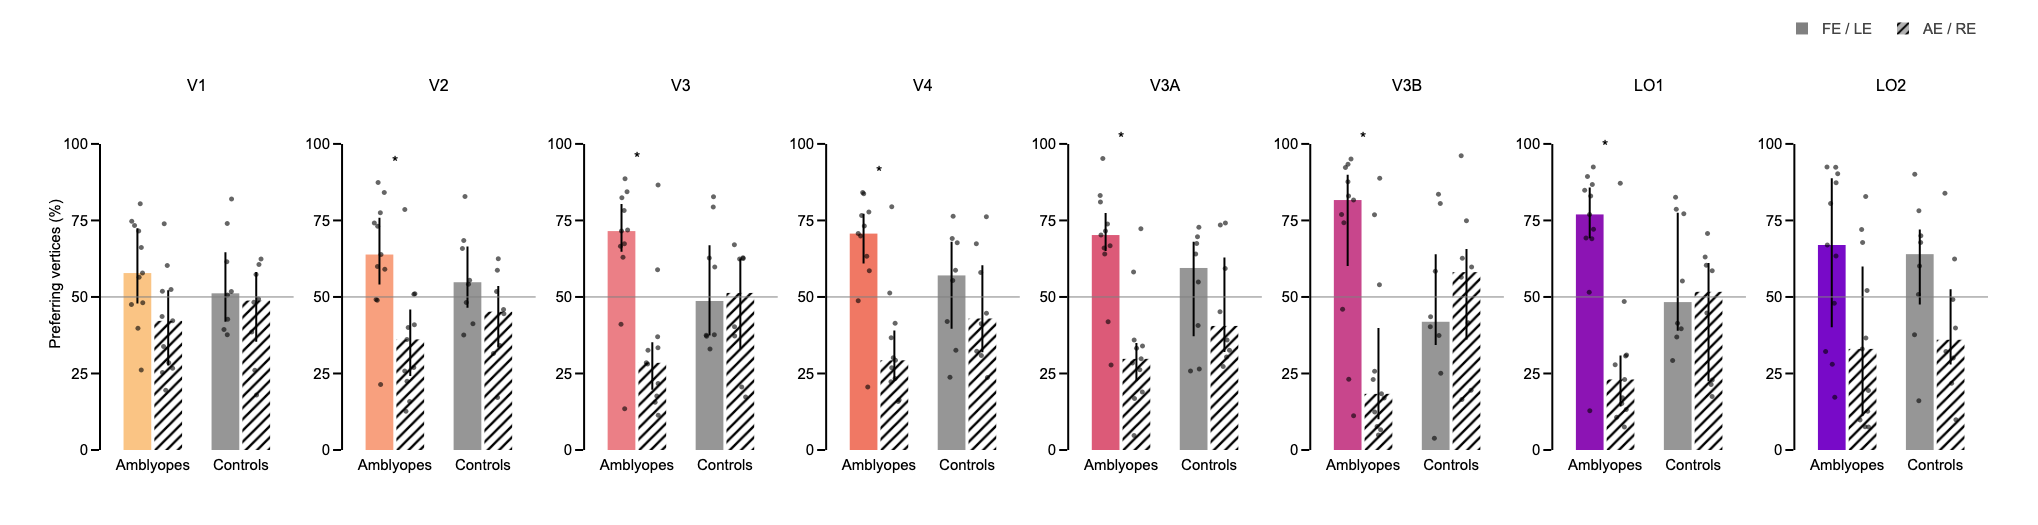

In [6]:
bar_figure(df_subjects, ['pref_FE-LE', 'pref_AE-RE'], s_pref, 'Preferring vertices (%)', np.linspace(0, 100, 5), '{:.0f}',
           'od_final_fig1_pref_percent{}'.format(fig_suffix), legends=['FE / LE', 'AE / RE'], patterns=['', '/'], ref=50)

## Figure 2 — strength of the ocular dominance

Weighted median of the vertex OD index (0 = both eyes equal; +0.1 = FE response 1.22 times the AE response). Same tests as Figure 1 with H0 = 0.

In [7]:
s_od = within_tests(df_subjects, 'od_index', 0)
s_od[['median_patients', 'p_patients_fdr', 'median_controls', 'p_controls_fdr', 'BF01_controls']].round(3)

,median_patients,p_patients_fdr,median_controls,p_controls_fdr,BF01_controls
roi,,,,,
V1,0.020,0.117,0.007,0.848,2.474
V2,0.084,0.043,0.024,0.848,1.928
V3,0.132,0.043,0.006,0.848,2.726
V4,0.102,0.043,0.033,0.848,2.490
V3A,0.126,0.020,0.020,0.848,2.828
V3B,0.120,0.118,-0.041,0.848,2.044
LO1,0.136,0.020,-0.013,1.000,2.972
LO2,0.126,0.120,0.059,0.848,1.218


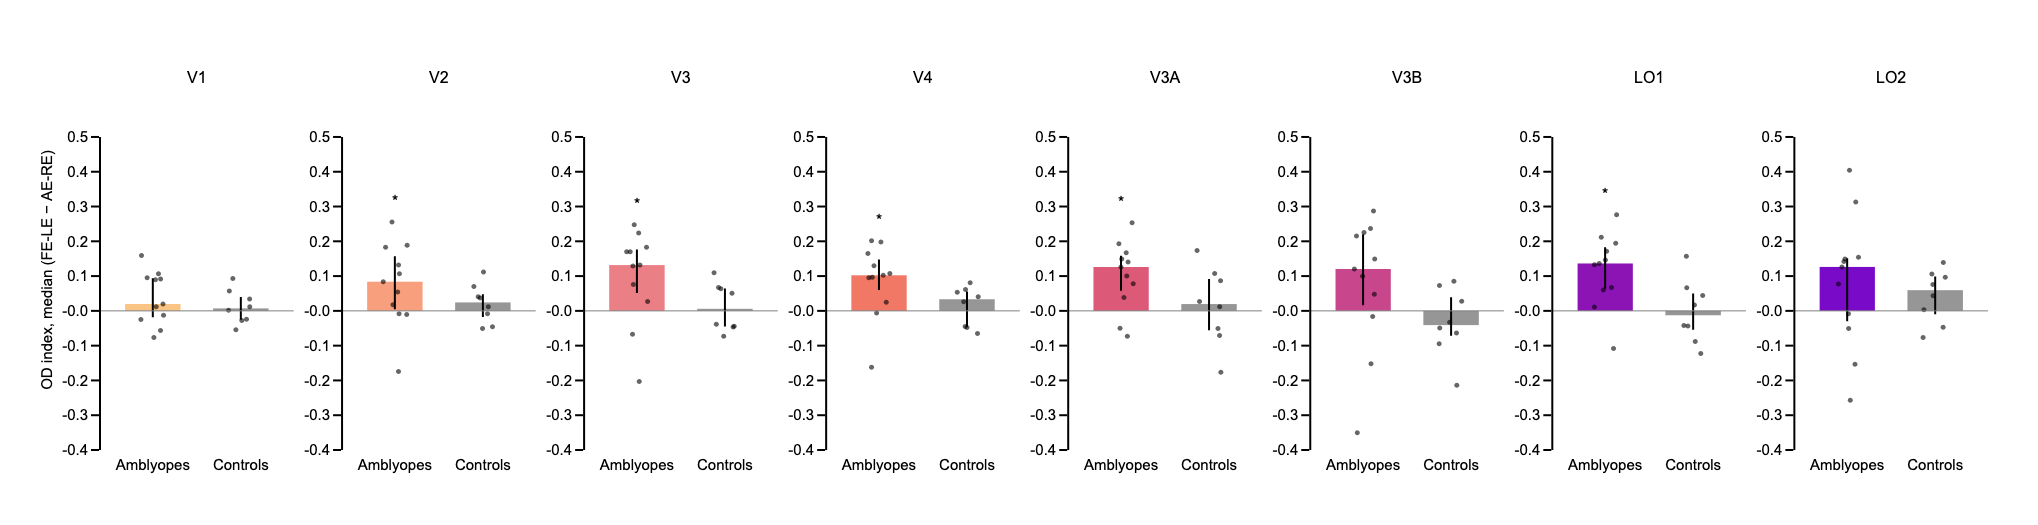

In [8]:
bar_figure(df_subjects, ['od_index'], s_od, 'OD index, median (FE-LE − AE-RE)',
           nice_ticks(df_subjects.od_index, 0.1), '{:.1f}', 'od_final_fig2_od_index{}'.format(fig_suffix), ref=0)

## Figure 3 — ocular dominance vs ΔlogMAR

ΔlogMAR = logMAR AE − logMAR FE (participants.tsv), amblyopes only. Spearman ρ per ROI, two-sided, FDR over the 8 ROIs. Line: least-squares fit (descriptive). Number = subject.

In [9]:
clin = participants[['participant_id', 'type', 'log_mar', 'log_mar_fellow']].rename(columns={'participant_id': 'subject'})
clin['log_mar'] = pd.to_numeric(clin.log_mar, errors='coerce')
clin['log_mar_fellow'] = pd.to_numeric(clin.log_mar_fellow, errors='coerce')
clin['delta_logmar'] = clin.log_mar - clin.log_mar_fellow
od_clin = df_subjects[df_subjects.group == 'patient'].merge(clin, on='subject', how='left')
print(clin[clin.subject.isin(patients)][['subject', 'type', 'log_mar', 'log_mar_fellow', 'delta_logmar']].to_string(index=False))


def clin_tests(measure, param='delta_logmar'):
    rows = []
    for roi in rois_to_keep:
        d = od_clin[od_clin.roi == roi].dropna(subset=[measure, param])
        rho, p = stats.spearmanr(d[measure], d[param]) if len(d) > 4 else (np.nan, np.nan)
        rows.append({'roi': roi, 'n': len(d), 'rho': rho, 'p': p})
    s = pd.DataFrame(rows).set_index('roi')
    s['p_fdr'] = bh_fdr(s.p)
    return s


def scatter_figure(measure, s, y_title, fn_out, param='delta_logmar', x_title='ΔlogMAR (AE − FE)'):
    fig = make_subplots(rows=1, cols=cols, subplot_titles=rois_to_keep, horizontal_spacing=hor_spacing)
    for col_idx, roi in enumerate(rois_to_keep, start=1):
        d = od_clin[od_clin.roi == roi].dropna(subset=[measure, param])
        fig.add_trace(go.Scatter(x=d[param], y=d[measure], mode='markers+text', text=d.subject.str[-2:],
                                 textposition='top center', textfont=dict(size=9), showlegend=False,
                                 marker=dict(size=9, color=roi_colors_rgb[roi], line=dict(width=1, color='black'))),
                      row=1, col=col_idx)
        if len(d) > 2:
            a, b = np.polyfit(d[param], d[measure], 1)
            xs = np.array([d[param].min(), d[param].max()])
            fig.add_trace(go.Scatter(x=xs, y=a * xs + b, mode='lines', line=dict(color='black', width=1.5), showlegend=False),
                          row=1, col=col_idx)
        xref, yref = 'x{}'.format('' if col_idx == 1 else col_idx), 'y{}'.format('' if col_idx == 1 else col_idx)
        fig.add_annotation(x=0.02, y=0.98, xref='{} domain'.format(xref), yref='{} domain'.format(yref), xanchor='left',
                           yanchor='top', showarrow=False, font=dict(size=12),
                           text='ρ = {:.2f}{}<br>p<sub>FDR</sub> = {:.3f}'.format(s.loc[roi, 'rho'], stars(s.loc[roi, 'p_fdr']),
                                                                              s.loc[roi, 'p_fdr']))
    fig.update_xaxes(title_text=x_title, showline=True)
    fig.update_yaxes(showline=True)
    fig.update_yaxes(title_text=y_title, row=1, col=1)
    fig.update_layout(template=fig_template, height=fig_height, width=fig_width,
                      margin_l=fig_margin[0], margin_t=fig_margin[1] + 40, margin_r=fig_margin[2], margin_b=fig_margin[3] + 30)
    fig.show()
    fig.write_image('{}/{}.pdf'.format(fig_dir, fn_out))

subject  type  log_mar  log_mar_fellow  delta_logmar
 sub-01 micro     0.32            0.06          0.26
 sub-02 micro     0.62            0.06          0.56
 sub-03 strab     0.58            0.14          0.44
 sub-04 strab     0.38            0.08          0.30
 sub-05 strab     0.70            0.00          0.70
 sub-06 strab     0.36            0.06          0.30
 sub-08 strab     1.00            0.10          0.90
 sub-09 strab     0.72            0.02          0.70
 sub-10 strab     0.56             NaN           NaN
 sub-11 strab     0.42            0.06          0.36
 sub-12 micro     0.38            0.08          0.30


OD index vs ΔlogMAR
      n    rho      p  p_fdr
roi                         
V1   10  0.240  0.504  0.733
V2   10  0.462  0.179  0.733
V3   10  0.382  0.277  0.733
V4   10  0.339  0.339  0.733
V3A  10  0.154  0.671  0.767
V3B  10  0.289  0.418  0.733
LO1  10  0.215  0.550  0.733
LO2  10  0.012  0.973  0.973


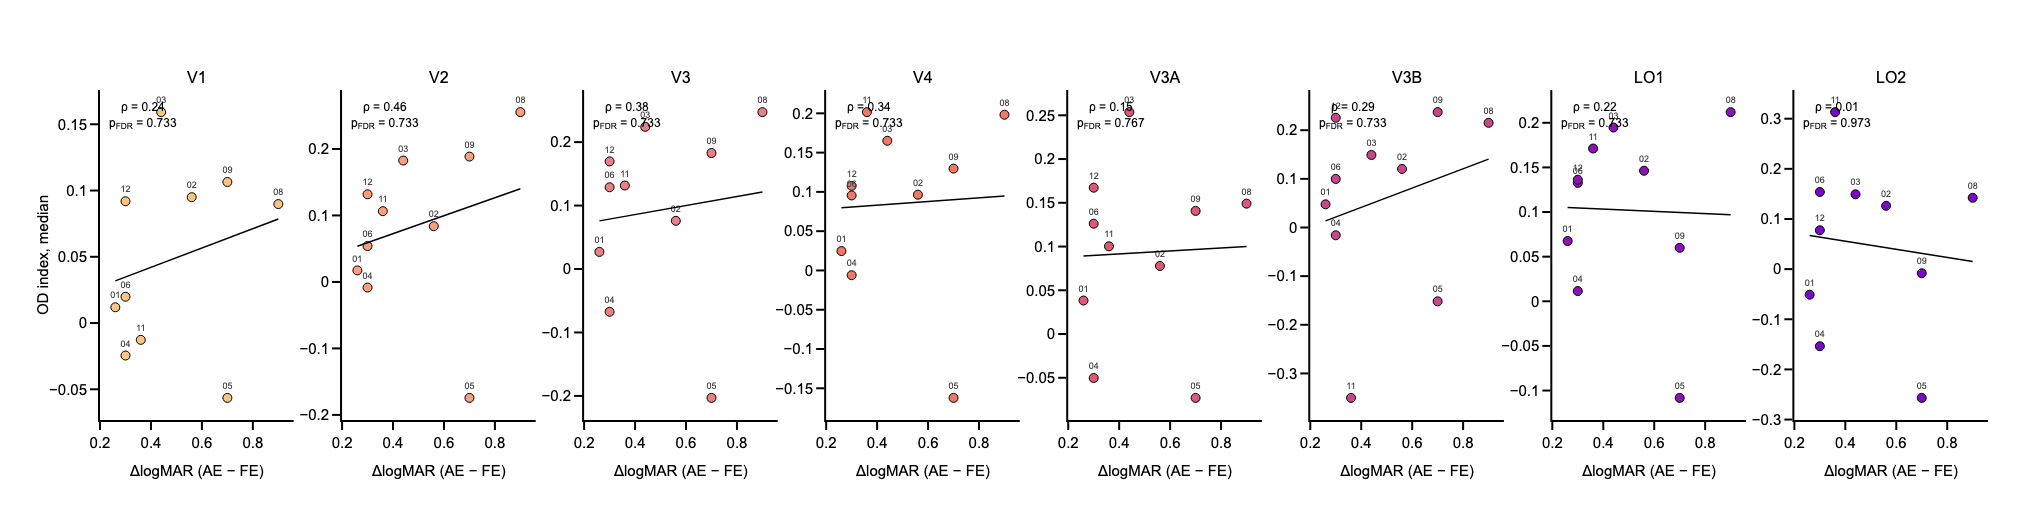

In [10]:
s_clin_od = clin_tests('od_index')
print('OD index vs ΔlogMAR')
print(s_clin_od.round(3).to_string())
scatter_figure('od_index', s_clin_od, 'OD index, median', 'od_final_fig3a_od_index_vs_dlogmar{}'.format(fig_suffix))

% vertices preferring FE vs ΔlogMAR
      n    rho      p  p_fdr
roi                         
V1   10  0.357  0.311  0.623
V2   10  0.486  0.154  0.623
V3   10  0.394  0.260  0.623
V4   10  0.468  0.173  0.623
V3A  10 -0.080  0.826  0.826
V3B  10  0.135  0.709  0.826
LO1  10  0.148  0.684  0.826
LO2  10  0.086  0.813  0.826


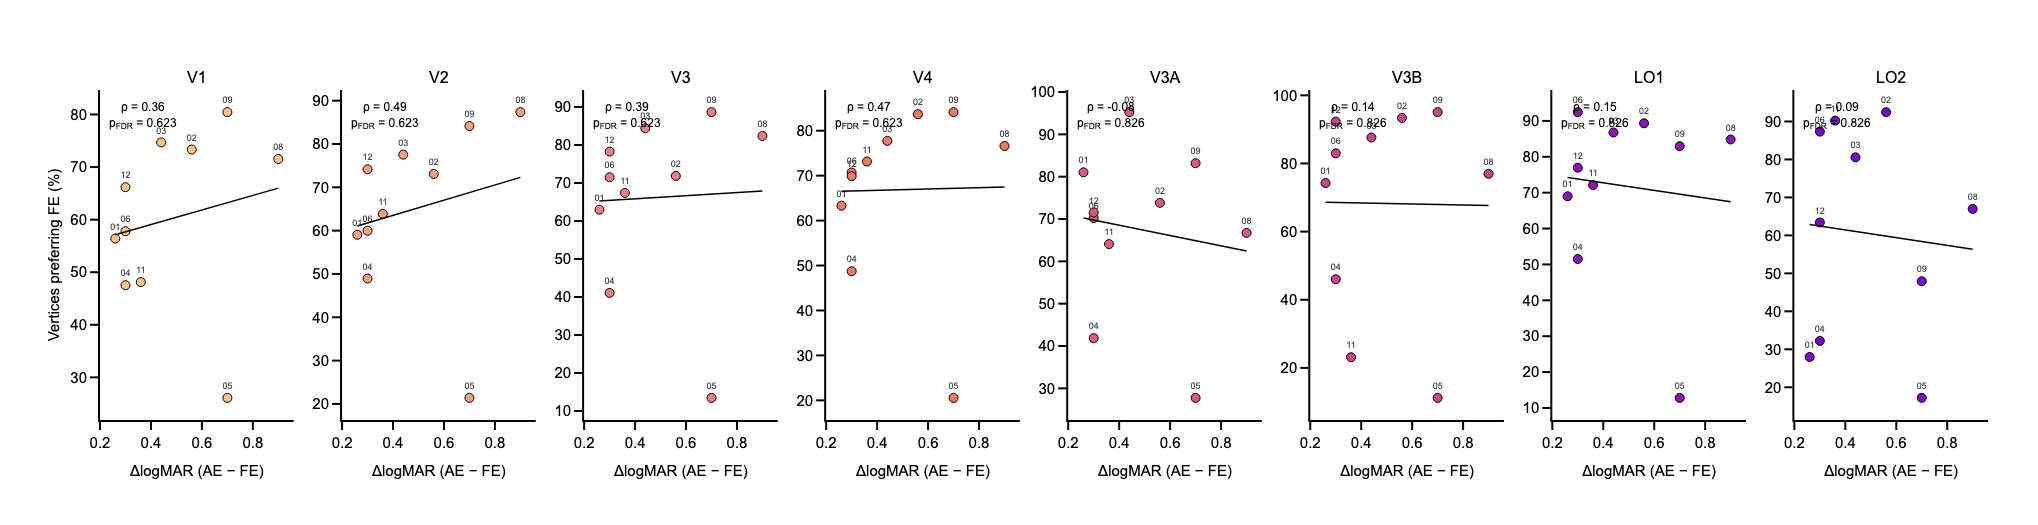

In [11]:
s_clin_pref = clin_tests('pref_FE-LE')
print('% vertices preferring FE vs ΔlogMAR')
print(s_clin_pref.round(3).to_string())
scatter_figure('pref_FE-LE', s_clin_pref, 'Vertices preferring FE (%)', 'od_final_fig3b_pref_vs_dlogmar{}'.format(fig_suffix))

## Figure 4 — pRF size and pCM as a function of eccentricity

Group TSVs made on the cluster by `make_ecc_size_pcm_tsv.py`, figure by `eyes_ecc_size_pcm_plot` as in `make_ecc_size_pcm_fig.py`. Amblyopes (AE, FE, with the controls' CTRL curve) and controls (LE, RE). These group TSVs use the groups of settings.yml (sub-05 as labelled), whatever `sub05_version`.

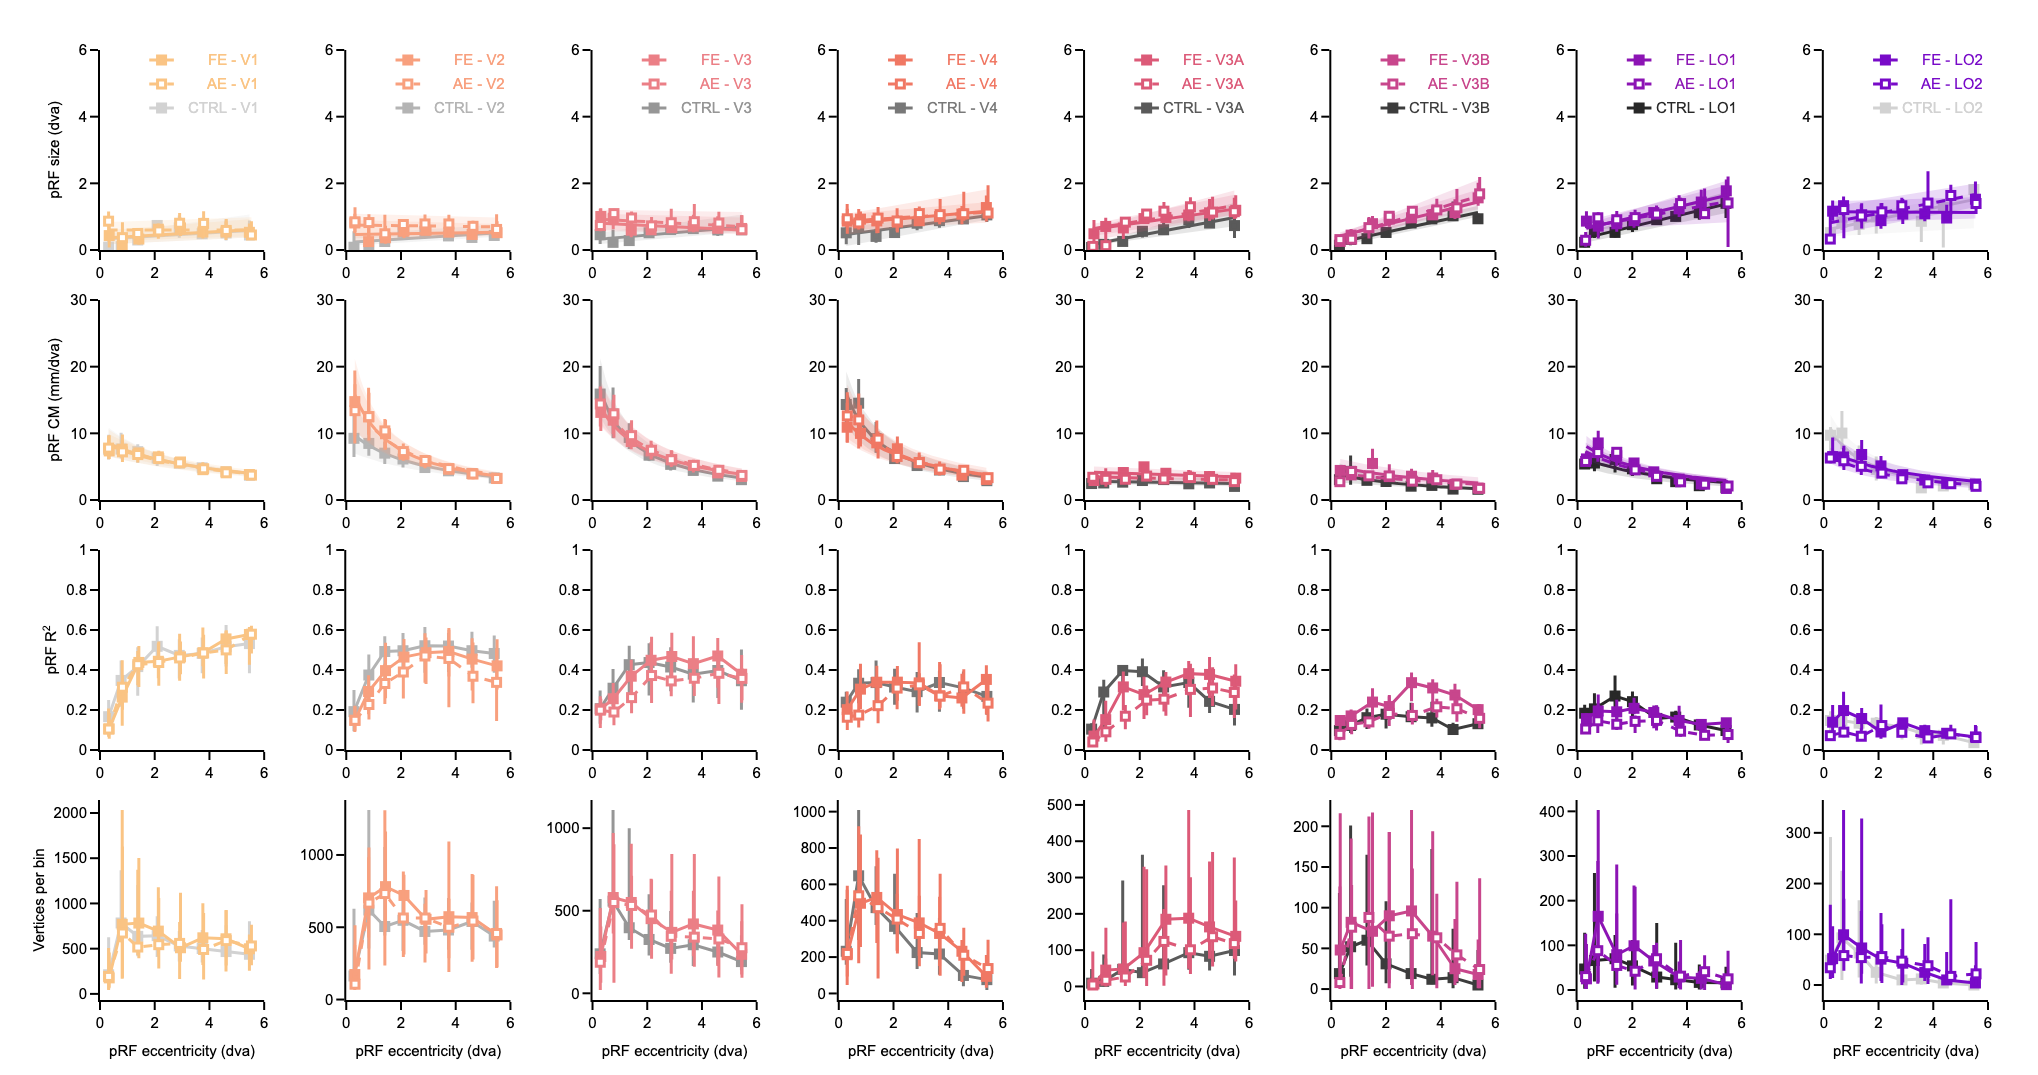

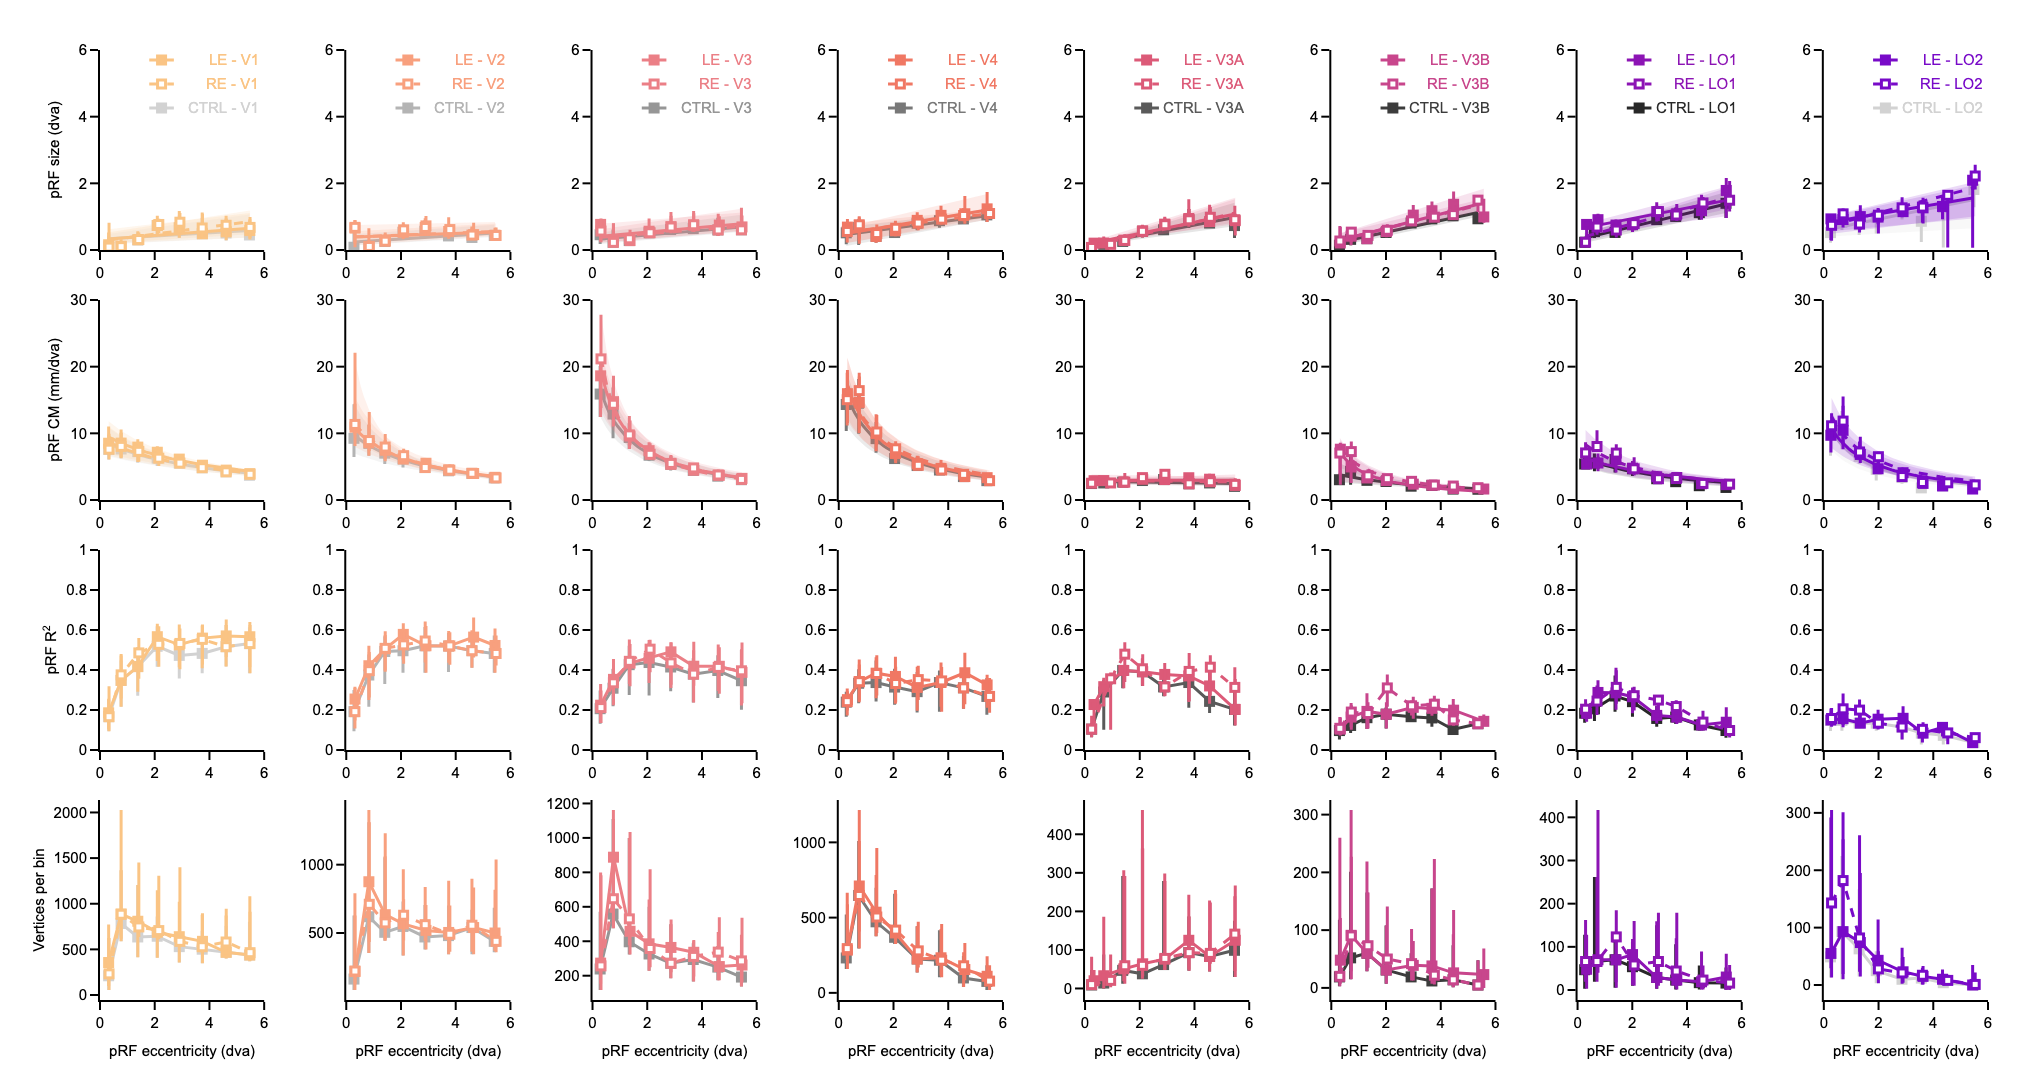

In [12]:
ecc_spec = 'task-BarsBarsRingsWedges_fmriprep_dct_psc_concat_rois-group-mmp'
ecc_tsv = '{}/{}/fsnative/{}/tsv/{}_{}_ecc-size-pcm.tsv'
figure_info = analysis_info.copy()
figure_info['rois'] = list(analysis_info['rois-group-mmp'].keys())

df_ecc = {g: pd.read_table(ecc_tsv.format(pp_dir, g, output_folder, g, ecc_spec), sep='\t')
          for g in ['group-patient', 'group-control']}
df_ctrl = df_ecc['group-control'][df_ecc['group-control'].eye_condition == 'CTRL'].copy()

for g, subject_group, ctrl in [('group-patient', 'patient', df_ctrl), ('group-control', 'control', None)]:
    figure_info['subject_group'] = subject_group
    fig = project_plot_utils.eyes_ecc_size_pcm_plot(df=df_ecc[g], figure_info=figure_info, rsq2use='prf_rsq', df_ctrl=ctrl)
    fig.show()
    fig.write_image('{}/od_final_fig4_ecc_size_pcm_{}.pdf'.format(fig_dir, g))